# 1. Setup

## 1.1 Install Dependencies


In [1]:
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("OpenCV:", cv2.__version__)
print("Matplotlib imported successfully")

TensorFlow: 2.21.0
OpenCV: 5.0.0
Matplotlib imported successfully


## 1.2 Import Standard  dependencies


In [2]:
!which python
!which python3
!pip show opencv-python

/Users/bhanupratap/tfenv/bin/python
/Users/bhanupratap/tfenv/bin/python3
Name: opencv-python
Version: 5.0.0.93
Summary: Wrapper package for OpenCV python bindings.
Home-page: https://github.com/opencv/opencv-python
Author: 
Author-email: 
License: Apache 2.0
Location: /Users/bhanupratap/tfenv/lib/python3.12/site-packages
Requires: numpy
Required-by: deepface, retina-face


In [3]:
import sys
import cv2

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("OpenCV version:", cv2.__version__)

Python executable: /Users/bhanupratap/tfenv/bin/python3.12
Python version: 3.12.13 (main, Mar  3 2026, 12:39:30) [Clang 17.0.0 (clang-1700.6.4.2)]
OpenCV version: 5.0.0


In [4]:
# import standard dependencies 
import cv2
import os
import random
import numpy as np
from matplotlib import pyplot as plt

In [5]:
#plt.imshow??

the Model we are going to buil is called # "Siamese neural Network"

In [6]:
#import tensorflow dependencies 
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Layer, Conv2D, Dense, MaxPooling2D, Input , Flatten
import tensorflow as tf

In [7]:
# "we donot need this" 
# Model(inputs =[inputimage, verificatioimage],outputs=[1,0])

In [8]:
# "we dont need this "
# class  L1Dist(Layer)
# (Input(shape = )


## 1.3 Set GPU growth

 mac doesnt support so we skipping it


## 1.4 Create Folder Structure


In [9]:
#setup paths
POS_PATH = os.path.join('data','positive')
NEG_PATH = os.path.join('data', 'negative')
ANC_PATH = os.path.join('data', 'anchor')

In [10]:
POS_PATH

'data/positive'

# Make directiories
os.makedirs( POS_PATH)
os.makedirs( NEG_PATH)
os.makedirs( ANC_PATH)

# 2. Collect Positives and Anchors

## 2.1 Untar Labelled  Faces in the wild Dataset

In [11]:
 # uncompress the faces in wild dataset
! tar -xf archive.zip

tar: Error opening archive: Failed to open 'archive.zip'


for directory in os.listdir('lfw'):
    dir_path = os.path.join('lfw', directory)
    if not os.path.isdir(dir_path):
        continue  # skip .DS_Store and any other stray files
    for file in os.listdir(dir_path):
        EX_PATH = os.path.join('lfw', directory, file)
        NEW_PATH = os.path.join(NEG_PATH, file)
        os.replace(EX_PATH, NEW_PATH)

In [12]:
# that fix for [Errno 20] Not a directory: 'lfw/.DS_Store'
! find lfw -name '.DS_Store' -delete

find: lfw: No such file or directory


for directory in os.listdir('lfw'):
    for files in os.listdir(os.path.join('lfw',directory)):
        print(os.path.join('lfw',directory,file))
        print(os.path.join(NEG_PATH,file))

## 2.2 Collecting Positive and Anchor classes 


In [13]:
!pip show opencv-python opencv-python-headless

Name: opencv-python
Version: 5.0.0.93
Summary: Wrapper package for OpenCV python bindings.
Home-page: https://github.com/opencv/opencv-python
Author: 
Author-email: 
License: Apache 2.0
Location: /Users/bhanupratap/tfenv/lib/python3.12/site-packages
Requires: numpy
Required-by: deepface, retina-face


In [14]:
# import uuid library to generate unique image names 
import uuid

In [15]:
os.path.join(ANC_PATH,'{}.jpg'.format(uuid.uuid1()))



'data/anchor/7682b19a-8d17-11f1-9516-16f5598afa7b.jpg'

In [ ]:
# Establish connection to the Webcam
cap = cv2.VideoCapture(0)

# Set webcam resolution
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        print("Failed to grab frame.")
        break

    # Get frame dimensions
    h, w = frame.shape[:2]

    # Centre of the frame
    cx = w // 2
    cy = h // 2

    # Crop a larger square for a wider field of view
    crop_size = 600

    x1 = max(0, cx - crop_size // 2)
    y1 = max(0, cy - crop_size // 2)
    x2 = min(w, cx + crop_size // 2)
    y2 = min(h, cy + crop_size // 2)

    # Crop and resize to 250x250
    frame = frame[y1:y2, x1:x2]
    frame = cv2.resize(frame, (250, 250))

    # Show image
    cv2.imshow('Image Collection', frame)

    # Read keyboard input once
    key = cv2.waitKey(1) & 0xFF

    # Collect anchor images
    if key == ord('a'):
        imgname = os.path.join(ANC_PATH, '{}.jpg'.format(uuid.uuid1()))
        cv2.imwrite(imgname, frame)
        print("Anchor image saved.")

    # Collect positive images
    elif key == ord('p'):
        imgname = os.path.join(POS_PATH, '{}.jpg'.format(uuid.uuid1()))
        cv2.imwrite(imgname, frame)
        print("Positive image saved.")

    # Exit
    elif key == ord('c'):
        break

# Release webcam and close windows
cap.release()
cv2.destroyAllWindows()

# 3. Load and Preprocess Images

## 3.1 Get Image Directories 

In [16]:
anchor = tf.data.Dataset.list_files(os.path.join(ANC_PATH, "*.jpg")).take(300)
positive = tf.data.Dataset.list_files(os.path.join(POS_PATH, "*.jpg")).take(300)
negative = tf.data.Dataset.list_files(os.path.join(NEG_PATH, "*.jpg")).take(300)

In [17]:
dir_test = anchor.as_numpy_iterator()


In [18]:
print(dir_test.next())

b'data/anchor/0843c96c-8a7e-11f1-909c-16f5598afa7c.jpg'


## 3.2 Preprocessing - Scale and Resizing 

In [19]:
def preprocess(file_path):
    # Read image from file
    byte_img = tf.io.read_file(file_path)

    # Decode JPEG
    img = tf.io.decode_jpeg(byte_img)

    # Resize image
    img = tf.image.resize(img, (100, 100))

    # Normalize pixel values
    img = img / 255.0

    return img

In [20]:
img = preprocess('data/anchor/c4d2515a-88e1-11f1-92d3-16f5598afa7b.jpg')

In [21]:
img.numpy().max()

np.float32(1.0)

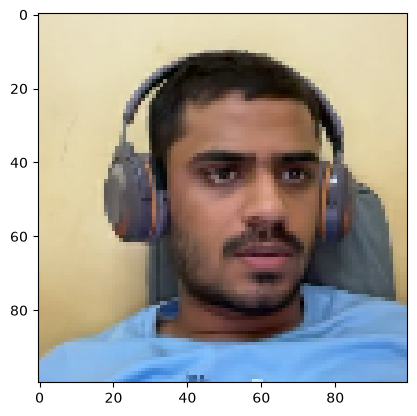

In [22]:
plt.imshow(img)

## 3.3 create labbeled dataset

In [23]:
# (anchor,positive)=> 1,1,1,1,1
# (anchor,negative) => 0,0,0,0,0

In [24]:
#class_labels = tf.data.Dataset.from_tensor_slices(tf.zeros(len(anchor)))

In [25]:
#iterator_labs = class_labels.as_numpy_iterator()

In [26]:
#iterator_labs.next()

In [27]:
positives = tf.data.Dataset.zip((anchor,positive, tf.data.Dataset.from_tensor_slices(tf.ones(len(anchor)))))
negatives = tf.data.Dataset.zip((anchor,negative, tf.data.Dataset.from_tensor_slices(tf.zeros(len(anchor)))))
data = positives.concatenate(negatives)

In [28]:
samples = data.as_numpy_iterator()


In [29]:
exampple  =samples.next()

In [30]:
exampple

(b'data/anchor/5cbeb2c0-88e1-11f1-8fb1-16f5598afa7b.jpg',
 b'data/positive/5a279b1c-88e1-11f1-8fb1-16f5598afa7b.jpg',
 np.float32(1.0))

## 3.4 Build Train and Test Partition

In [31]:
def preprocess_twin(input_img,validation_img,label):
    return (preprocess(input_img), preprocess(validation_img),label)

In [32]:
 res = preprocess_twin(*exampple)

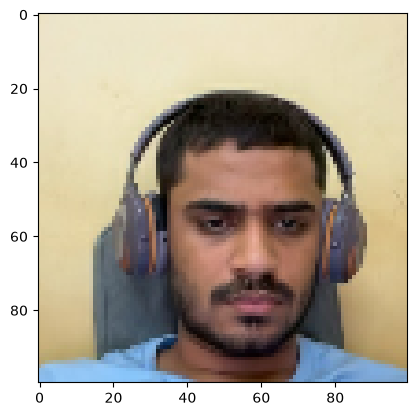

In [33]:
plt.imshow(res[0])

In [34]:
res[2]

np.float32(1.0)

In [35]:
#built dataloader pipeline
data = data.map(preprocess_twin)
data = data.cache()
data = data.shuffle(buffer_size= 1024)


In [36]:
round(len(data)*.7)

165

In [37]:
data

<_ShuffleDataset element_spec=(TensorSpec(shape=(100, 100, None), dtype=tf.float32, name=None), TensorSpec(shape=(100, 100, None), dtype=tf.float32, name=None), TensorSpec(shape=(), dtype=tf.float32, name=None))>

In [38]:
# training partition 
train_data = data.take(round(len(data)*.7))
train_data = train_data.batch(16)
train_data = train_data.prefetch(8)

In [39]:
train_samples = train_data.as_numpy_iterator()

In [40]:
train_sample = train_samples.next()


In [41]:
len(train_sample[0])

16

In [42]:
round(len(data)*.7)

165

In [43]:
# testing Partition
test_data = data.skip(round(len(data)*.7))
test_data = test_data.take(round(len(data)*.3))
test_data = test_data.batch(16)
test_data = test_data.prefetch(8)

# 4. Model Engineering

## 4.1 Build Embedding Layer

In [44]:
inp = Input(shape=(100,100,3),name='input_image')

In [45]:
c1 = Conv2D(64,(10,10),activation='relu')(inp)

In [46]:
m1 = MaxPooling2D(64,(2,2),padding='same')(c1)

In [47]:
c2 = Conv2D(128,(7,7), activation='relu')(m1)
m2 = MaxPooling2D(64,(2,2),padding='same')(c2)

In [48]:
c3 = Conv2D(128,(4,4), activation='relu')(m2)
m3 = MaxPooling2D(64,(2,2), padding='same')(c3)

In [49]:
c4 = Conv2D(256, (4,4), activation='relu')(m3)
f1 = Flatten()(c4)
d1 = Dense(4096, activation='sigmoid')(f1)

In [50]:
c4

<KerasTensor shape=(None, 6, 6, 256), dtype=float32, sparse=False, ragged=False, name=keras_tensor_6>

In [51]:
6*6*256

9216

In [52]:
f1

<KerasTensor shape=(None, 9216), dtype=float32, sparse=False, ragged=False, name=keras_tensor_7>

In [53]:
model = Model(inputs= [inp],outputs=[d1], name='embedding')


In [54]:
model.summary()

Model: "embedding"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 91, 91, 64)     │        19,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 46, 46, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 40, 40, 128)    │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 17, 17, 128)    │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 6, 6, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │    37,752,832 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,960,448 (148.62 MB)

 Trainable params: 38,960,448 (148.62 MB)

 Non-trainable params: 0 (0.00 B)

In [55]:
def make_embedding():
    inp = Input(shape=(100,100,3),name='input_image')

    # First Block 
    c1 = Conv2D(64,(10,10), activation='relu')(inp)
    m1 = MaxPooling2D(64,(2,2),padding='same')(c1)

    #Second Block
    c2 = Conv2D(128,(7,7), activation='relu')(m1)
    m2 = MaxPooling2D(64,(2,2),padding='same')(c2)

    # Third Block
    c3 = Conv2D(128,(4,4), activation='relu')(m2)
    m3 = MaxPooling2D(64,(2,2), padding='same')(c3)

    # Final Embedding  Block
    c4 = Conv2D(256, (4,4), activation='relu')(m3)
    f1 = Flatten()(c4)
    d1 = Dense(4096, activation='sigmoid')(f1)
    

    
    return Model(inputs=inp, outputs=d1, name='embedding')


In [56]:
embedding  = make_embedding()

In [57]:
embedding.summary()

Model: "embedding"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 91, 91, 64)     │        19,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 46, 46, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 40, 40, 128)    │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 17, 17, 128)    │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 6, 6, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4096)           │    37,752,832 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,960,448 (148.62 MB)

 Trainable params: 38,960,448 (148.62 MB)

 Non-trainable params: 0 (0.00 B)

## 4.2 Build Distance Layer


In [58]:
class L1Dist(Layer):

    #Innit method inheritance 
    def __init__(self, **kwargs):
        super().__init__()
        
    # Magic Happens Here - similarity calculation
    def call(self, input_embedding, validation_embadding):
        return tf.math.abs(input_embedding -  validation_embadding)

In [59]:
l1 = L1Dist()

In [60]:
l1(input_embedding , validation_embedding)

NameError: name 'input_embedding' is not defined

## 4.3 Make Siamese Model

In [61]:
input_image = Input(name='input_img' , shape=(100,100,3))
validation_image = Input(name='validation_img' , shape=(100,100,3))

In [62]:
inp_embedding = embedding(input_image)
val_embedding = embedding(validation_image)

In [63]:
l1(inp_embedding , val_embedding)

<KerasTensor shape=(None, 4096), dtype=float32, sparse=False, ragged=False, name=keras_tensor_20>

In [64]:
siamese_layer = L1Dist()

In [65]:
distances = siamese_layer(inp_embedding,val_embedding)

In [66]:
classifier = Dense(1,activation='sigmoid')(distances)

In [67]:
classifier

<KerasTensor shape=(None, 1), dtype=float32, sparse=False, ragged=False, name=keras_tensor_22>

In [68]:
siamese_network = Model(inputs =[input_image,validation_image],outputs=classifier, name='SiameseNetwork')

In [69]:
siamese_network.summary()

Model: "SiameseNetwork"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_img           │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ validation_img      │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 4096)      │ 38,960,448 │ input_img[0][0],  │
│ (Functional)        │                   │            │ validation_img[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ l1_dist_1 (L1Dist)  │ (None, 4096)      │          0 │ embedding[0][0],  │
│                     │                   │            │ embedding[1][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │      4,097 │ l1_dist_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 38,964,545 (148.64 MB)

 Trainable params: 38,964,545 (148.64 MB)

 Non-trainable params: 0 (0.00 B)

In [70]:
def make_siamese_model():


    # Anchor Image input in the network
    input_image = Input(name='input_img' , shape=(100,100,3))

    # Validation Image in the network 
    validation_image = Input(name='validation_img' , shape=(100,100,3))

    # combine siamese distance components 
    siamese_layer= L1Dist()
    siamese_layer._name = 'distance'
    distances = siamese_layer(embedding(input_image), embedding(validation_image))

    # classification layer
    classifier = Dense(1,activation='sigmoid')(distances)

    return Model(inputs =[input_image,validation_image],outputs=classifier, name='SiameseNetwork')
             

In [71]:
siamese_model = make_siamese_model()

In [72]:
siamese_model.summary()

Model: "SiameseNetwork"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_img           │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ validation_img      │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 4096)      │ 38,960,448 │ input_img[0][0],  │
│ (Functional)        │                   │            │ validation_img[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ l1_dist_2 (L1Dist)  │ (None, 4096)      │          0 │ embedding[2][0],  │
│                     │                   │            │ embedding[3][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │      4,097 │ l1_dist_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 38,964,545 (148.64 MB)

 Trainable params: 38,964,545 (148.64 MB)

 Non-trainable params: 0 (0.00 B)

# 5. Training

## 5.1 Setup Loss and Optimizer

In [73]:
binary_cross_loss = tf.losses.BinaryCrossentropy()

In [74]:
opt = tf.keras.optimizers.Adam(1e-4) # 0.0001

## 5.2 Establish Checkpoints 

In [75]:
checkpoint_dir = './training_checkpoints'
checkpoint_prefix = os.path.join(checkpoint_dir,'ckpt')
checkpoint = tf.train.Checkpoint(opt=opt, siamese_model = siamese_model)

## 5.3 Build Train Step Function

In [76]:
test_batch = train_data.as_numpy_iterator()

In [77]:
batch_1 = test_batch.next()

In [78]:
X = batch_1[:2]

In [79]:
Y = batch_1[2]

In [80]:
Y

array([0., 0., 1., 0., 0., 1., 0., 0., 0., 1., 0., 0., 1., 1., 0., 1.],
      dtype=float32)

In [81]:
@tf.function
def train_step(batch):

    # Record all of our operations
    with tf.GradientTape() as tape:
        # get anchor and positive/negative images
        X = batch[:2]
        # get Label
        y = batch[2]

        # Forward Pass
        yhat = siamese_model(X,training = True )
        # Calculation Loss
        loss =  binary_cross_loss(y, yhat)
    tf.print(loss)
    # calculate Gradients
    grad = tape.gradient(loss, siamese_model.trainable_variables)
    # Calculate updated weights and apply to siamese model
    opt.apply_gradients(zip(grad,  siamese_model.trainable_variables))

    # return loss
    return loss


## 5.4 Build Training Loop

In [82]:
def train(data, EPOCHS):
    #loop through epochs 
    for epoch in range (1, EPOCHS+1):
        print('\n Epoch {}/{}'.format(epoch, EPOCHS))
        progbar = tf.keras.utils.Progbar(len(data))

        #loop through each batch
        for idx, batch in enumerate(data):
            #Run Train step here
            train_step(batch)
            progbar.update(idx+1)

        # Save Checkpoints
        if epoch % 10 == 0:
            checkpoint.save(file_prefix=checkpoint_prefix)

## 5.5 Train the model

In [85]:
EPOCHS = 50

In [86]:
train(train_data , EPOCHS)


 Epoch 1/50
0.694298863
 1/11 ━━━━━━━━━━━━━━━━━━━━ 34s 3s/step0.690874815
 2/11 ━━━━━━━━━━━━━━━━━━━━ 23s 3s/step0.684597969
 3/11 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step0.674002826
 4/11 ━━━━━━━━━━━━━━━━━━━━ 19s 3s/step0.655151784
 5/11 ━━━━━━━━━━━━━━━━━━━━ 16s 3s/step0.673304856
 6/11 ━━━━━━━━━━━━━━━━━━━━ 13s 3s/step0.587605715
 7/11 ━━━━━━━━━━━━━━━━━━━━ 10s 3s/step0.616790533
 8/11 ━━━━━━━━━━━━━━━━━━━━ 8s 3s/step 0.593869
 9/11 ━━━━━━━━━━━━━━━━━━━━ 5s 3s/step0.569627225
10/11 ━━━━━━━━━━━━━━━━━━━━ 2s 3s/step0.55170387
11/11 ━━━━━━━━━━━━━━━━━━━━ 29s 3s/step

 Epoch 2/50
0.611231804
 1/11 ━━━━━━━━━━━━━━━━━━━━ 27s 3s/step0.560852289
 2/11 ━━━━━━━━━━━━━━━━━━━━ 23s 3s/step0.536771
 3/11 ━━━━━━━━━━━━━━━━━━━━ 21s 3s/step0.628890395
 4/11 ━━━━━━━━━━━━━━━━━━━━ 18s 3s/step0.49932605
 5/11 ━━━━━━━━━━━━━━━━━━━━ 16s 3s/step0.535628915
 6/11 ━━━━━━━━━━━━━━━━━━━━ 13s 3s/step0.462804437
 7/11 ━━━━━━━━━━━━━━━━━━━━ 11s 3s/step0.516948223
 8/11 ━━━━━━━━━━━━━━━━━━━━ 8s 3s/step 0.472796679
 9/11 ━━━━━━━━━━━━━━━

# 6. Evaluate Model

## 6.1  Import Metrics

In [83]:
# Import metric calculations
from tensorflow.keras.metrics import Precision, Recall

## 6.2 Make Predictions

In [84]:
# Get a batch of test data
test_input, test_val, y_true = test_data.as_numpy_iterator().next()

In [85]:
# Make predictions 
y_hat = siamese_model.predict([test_input,test_val])
y_hat

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 905ms/step


array([[0.5007798 ],
       [0.5005709 ],
       [0.5022664 ],
       [0.5010609 ],
       [0.5005441 ],
       [0.5005978 ],
       [0.5020982 ],
       [0.501396  ],
       [0.5006176 ],
       [0.50089276],
       [0.50168395],
       [0.5006118 ],
       [0.5019113 ],
       [0.5007875 ],
       [0.50073093],
       [0.50077957]], dtype=float32)

In [86]:
# Post Processing the results
[1 if prediction > 0.5 else 0 for prediction in y_hat]

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

In [87]:
y_true

array([1., 1., 1., 1., 1., 1., 0., 1., 0., 1., 1., 1., 0., 0., 1., 1.],
      dtype=float32)

## 6.3 Calculating Metrics

In [88]:
# Create a metric object
m = Recall()

# Calculate the recall value 
m.update_state(y_true, y_hat)

# Return Recall Results
m.result().numpy()

np.float32(1.0)

In [89]:
# Create a metric object
m = Precision()

# Calculate the recall value 
m.update_state(y_true, y_hat)

# Return Recall Results
m.result().numpy()

np.float32(0.75)

## 6.4 Visualizing the results

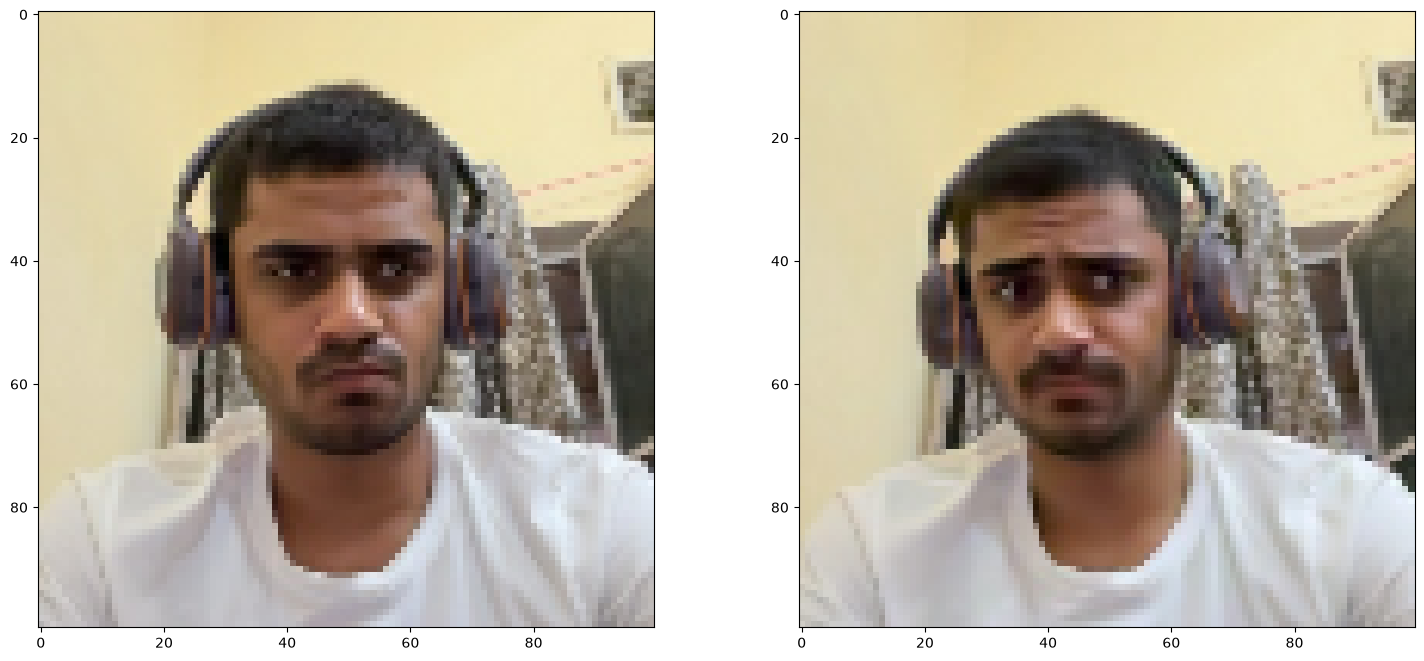

In [90]:
# set plot size
plt.figure(figsize=(18,8))

# set first subplot(number of rows,number of columns ,index)
plt.subplot(1,2,1)
plt.imshow(test_input[0])

# set second subplot
plt.subplot(1,2,2)
plt.imshow(test_val[0])

# renders planely
plt.show()

# 7. Save Model

In [91]:
# Save Weights
siamese_model.save('siamesemodel.h5')

In [92]:
# Reload Model
model = tf.keras.models.load_model('siamesemodel.h5',custom_objects={'L1Dist':L1Dist,'BinaryCrossentropy':tf.losses.BinaryCrossentropy})

In [93]:
# make predictions with reloaded images 
model.predict([test_input , test_val])

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 818ms/step


array([[0.5007798 ],
       [0.5005709 ],
       [0.5022664 ],
       [0.5010609 ],
       [0.5005441 ],
       [0.5005978 ],
       [0.5020982 ],
       [0.501396  ],
       [0.5006176 ],
       [0.50089276],
       [0.50168395],
       [0.5006118 ],
       [0.5019113 ],
       [0.5007875 ],
       [0.50073093],
       [0.50077957]], dtype=float32)

In [94]:
# View Model Summary
model.summary()

Model: "SiameseNetwork"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_img           │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ validation_img      │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 4096)      │ 38,960,448 │ input_img[0][0],  │
│ (Functional)        │                   │            │ validation_img[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ l1_dist_3 (L1Dist)  │ (None, 4096)      │          0 │ embedding[0][0],  │
│                     │                   │            │ embedding[1][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │      4,097 │ l1_dist_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 38,964,545 (148.64 MB)

 Trainable params: 38,964,545 (148.64 MB)

 Non-trainable params: 0 (0.00 B)

# 8. Real Time Test

## 8.1 Verification Function

In [95]:
application_data/verification_images

NameError: name 'application_data' is not defined

In [96]:
os.listdir(os.path.join('application_data', 'verification_images'))

['f462b12e-8a7d-11f1-909c-16f5598afa7c.jpg',
 'c76988ac-88e1-11f1-92d3-16f5598afa7b.jpg',
 '5ba668c4-88e1-11f1-8fb1-16f5598afa7b.jpg',
 '55badb3e-88e1-11f1-8fb1-16f5598afa7b.jpg',
 '002c546a-8a7e-11f1-909c-16f5598afa7c.jpg',
 'f686735a-8a7d-11f1-909c-16f5598afa7c.jpg',
 'fb5c48fa-8a7d-11f1-909c-16f5598afa7c.jpg',
 '5ae9806a-88e1-11f1-8fb1-16f5598afa7b.jpg',
 '03b5747c-8a7e-11f1-909c-16f5598afa7c.jpg',
 'cab87bee-88e1-11f1-92d3-16f5598afa7b.jpg',
 'c5185060-88e1-11f1-92d3-16f5598afa7b.jpg',
 '086229fc-8a7e-11f1-909c-16f5598afa7c.jpg',
 'ca114aa4-88e1-11f1-92d3-16f5598afa7b.jpg',
 'fceeacf8-8a7d-11f1-909c-16f5598afa7c.jpg',
 'fdb9bf10-8a7d-11f1-909c-16f5598afa7c.jpg',
 '03502a9a-8a7e-11f1-909c-16f5598afa7c.jpg',
 'c01bbd9a-88e1-11f1-92d3-16f5598afa7b.jpg',
 'c301cd92-88e1-11f1-92d3-16f5598afa7b.jpg',
 'c903830c-88e1-11f1-92d3-16f5598afa7b.jpg',
 'c3af15e2-88e1-11f1-92d3-16f5598afa7b.jpg',
 '5f3b4522-88e1-11f1-8fb1-16f5598afa7b.jpg',
 'c78e1cc6-88e1-11f1-92d3-16f5598afa7b.jpg',
 'fcbb34fe

In [97]:
os.path.join('application_data', 'input_image' , 'input_image.jpg')

'application_data/input_image/input_image.jpg'

In [98]:
for image in os.listdir(os.path.join('application_data', 'verification_images')):
    validation_img = preprocess(os.path.join('application_data', 'verification_images' , image))
    print(validation_img)

tf.Tensor(
[[[0.8833333  0.83235294 0.66764706]
  [0.88553923 0.83455884 0.6698529 ]
  [0.88235295 0.83137256 0.6666667 ]
  ...
  [0.94215685 0.89509803 0.73039216]
  [0.9458333  0.902451   0.7267157 ]
  [0.9411765  0.9098039  0.7294118 ]]

 [[0.8784314  0.827451   0.6627451 ]
  [0.88235295 0.83137256 0.6666667 ]
  [0.88235295 0.83137256 0.6666667 ]
  ...
  [0.9411765  0.8980392  0.72132355]
  [0.94509804 0.9019608  0.7223039 ]
  [0.94509804 0.9019608  0.72156864]]

 [[0.8813726  0.8303922  0.66568625]
  [0.88235295 0.83137256 0.6666667 ]
  [0.88235295 0.83137256 0.6666667 ]
  ...
  [0.94191176 0.8987745  0.72205883]
  [0.94509804 0.9019608  0.7223039 ]
  [0.94803923 0.904902   0.7245098 ]]

 ...

 [[0.8661765  0.84436274 0.827451  ]
  [0.8473039  0.8335784  0.8257353 ]
  [0.80759805 0.80710787 0.80735296]
  ...
  [0.7654412  0.75171566 0.7561275 ]
  [0.79044116 0.7877451  0.7973039 ]
  [0.8088235  0.81078434 0.82843137]]

 [[0.7948529  0.7745098  0.7590686 ]
  [0.84289217 0.8301471  0

In [99]:
def verify(model, detection_threshold , verification_threshold):
    #Build result array 
    results = []
    for image in os.listdir(os.path.join('application_data', 'verification_images')):
        input_img = preprocess(os.path.join('application_data', 'input_image' , 'input_image.jpg'))
        validation_img = preprocess(os.path.join('application_data', 'verification_images' , image))
        # Make Predictions
        result = model.predict(list(np.expand_dims([input_img, validation_img], axis=1)))
        results.append(result)



    #  Detection Threshold : Metric above which a prediction is considered positive
    detection = np.sum(np.array(results)>detection_threshold)
    
    # Verification Threshold : Proportion of positive predictions / total positive samples 
    verification =detection / len(os.listdir(os.path.join('application_data', 'verification_images')))
    verified = verification > verification_threshold
    
    return results , verified

## 8.2  Real Time Verification

In [100]:
# 1. Imports
import tensorflow as tf
import cv2
import os
import numpy as np
import uuid
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Layer

# 2. The custom layer class (required to load the model)
class L1Dist(Layer):
    def __init__(self, **kwargs):
        super().__init__()
    def call(self, input_embedding, validation_embedding):
        return tf.math.abs(input_embedding - validation_embedding)

# 3. Preprocessing function
def preprocess(file_path):
    byte_img = tf.io.read_file(file_path)
    img = tf.io.decode_jpeg(byte_img)
    img = tf.image.resize(img, (100, 100))
    img = img / 255.0
    return img

# 4. Verify function
def verify(model, detection_threshold, verification_threshold):
    results = []
    for image in os.listdir(os.path.join('application_data', 'verification_images')):
        input_img = preprocess(os.path.join('application_data', 'input_image', 'input_image.jpg'))
        validation_img = preprocess(os.path.join('application_data', 'verification_images', image))
        result = model.predict(list(np.expand_dims([input_img, validation_img], axis=1)))
        results.append(result)
    detection = np.sum(np.array(results) > detection_threshold)
    verification = detection / len(os.listdir(os.path.join('application_data', 'verification_images')))
    verified = verification > verification_threshold
    return results, verified

# 5. Load your already-trained model (fast — just reads weights from disk, no training)
model = tf.keras.models.load_model('siamesemodel.h5', custom_objects={'L1Dist': L1Dist, 'BinaryCrossentropy': tf.losses.BinaryCrossentropy})

In [103]:
# Establish connection to the Webcam
cap = cv2.VideoCapture(0)
# Set webcam resolution
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        print("Failed to grab frame.")
        break
    
    # Get frame dimensions
    h, w = frame.shape[:2]
    # Centre of the frame
    cx = w // 2
    cy = h // 2
    # Crop a larger square for a wider field of viewc
    crop_size = 600
    x1 = max(0, cx - crop_size // 2)
    y1 = max(0, cy - crop_size // 2)
    x2 = min(w, cx + crop_size // 2)
    y2 = min(h, cy + crop_size // 2)
    # Crop and resize to 250x250
    frame = frame[y1:y2, x1:x2]
    frame = cv2.resize(frame, (250, 250))
    
    cv2.imshow('verification', frame)
    
    key = cv2.waitKey(10) & 0xFF
    
    # Verification trigger
    if key == ord('v'):
        # Save input image to application_data/input_image folder
        cv2.imwrite(os.path.join('application_data', 'input_image', 'input_image.jpg'), frame)
        print("Verification image saved.")
        results, verified = verify(model, 0.4, 0.4)
        print(verified)
    
    if key == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

Verification image saved.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step

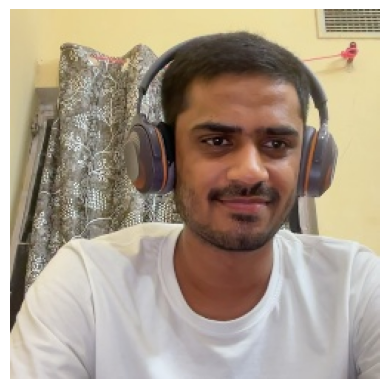

In [102]:

img = plt.imread(os.path.join('application_data', 'input_image', 'input_image.jpg'))
plt.imshow(img)
plt.axis('off')
plt.show()